# Probability, Distributions, and the Central Limit Theorem

Use simulation to build intuition for uncertainty and common distributions.

> 🧭 This notebook focuses on practical data work. Examples are intentionally compact and do not cover machine learning.

## Learning goals
- Distinguish a probability from a frequency observed in a sample.
- Simulate Bernoulli/binomial outcomes and inspect normal-like data.
- Understand expected value and variability.
- Demonstrate the Central Limit Theorem (CLT) through repeated sampling.

The CLT describes the sampling distribution of a suitably standardized sample mean under broad conditions; it does not say that the raw data must be normally distributed.

Observed heads rate: 0.509
Expected rate: 0.5


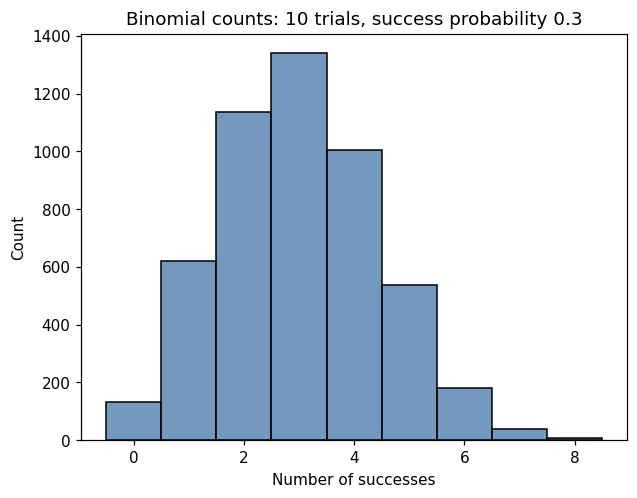

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

rng = np.random.default_rng(21)
flips = rng.binomial(n=1, p=0.5, size=1000)
print("Observed heads rate:", flips.mean())
print("Expected rate:", 0.5)

counts = rng.binomial(n=10, p=0.3, size=5000)
sns.histplot(counts, discrete=True, color="#4477AA")
plt.title("Binomial counts: 10 trials, success probability 0.3")
plt.xlabel("Number of successes")
plt.show()

## Normal and Poisson distributions
A normal distribution is often used for continuous measurements and measurement error. A Poisson distribution is commonly used for counts over a fixed interval when its assumptions are reasonable. A distributional fit should be checked, not assumed.

Normal mean / std: 49.99 8.13
Poisson mean / variance: 4.09 4.08


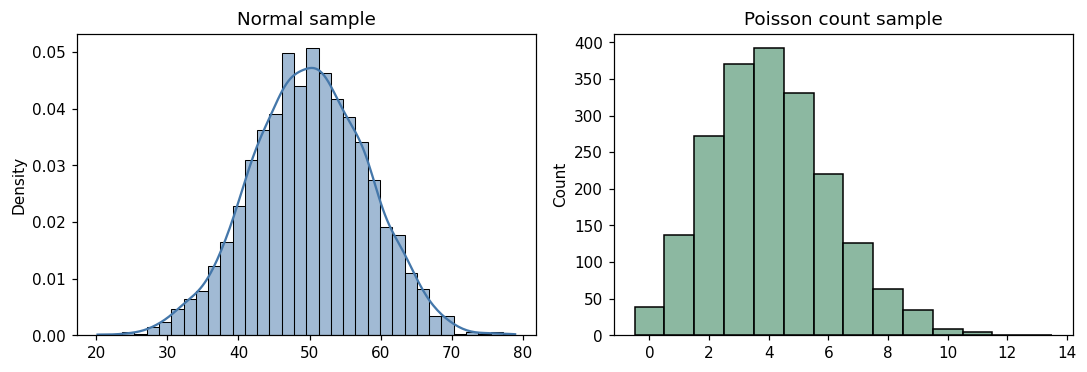

In [2]:
normal = rng.normal(loc=50, scale=8, size=2000)
counts = rng.poisson(lam=4, size=2000)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(normal, stat="density", kde=True, color="#4477AA", ax=axes[0])
axes[0].set_title("Normal sample")
sns.histplot(counts, discrete=True, color="#66A182", ax=axes[1])
axes[1].set_title("Poisson count sample")
plt.tight_layout()
plt.show()
print("Normal mean / std:", round(normal.mean(), 2), round(normal.std(ddof=1), 2))
print("Poisson mean / variance:", round(counts.mean(), 2), round(counts.var(ddof=1), 2))

## Central Limit Theorem by simulation
Use a strongly right-skewed population. Means from larger repeated samples tend to have a more concentrated and often more bell-shaped sampling distribution. This is a qualitative simulation, not a universal guarantee for every sample size.

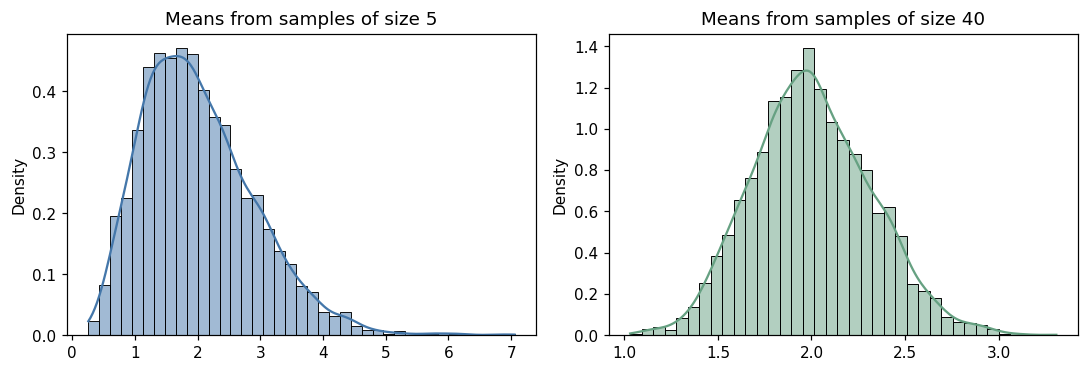

In [3]:
population = rng.exponential(scale=2.0, size=200_000)
means_small = np.array([rng.choice(population, size=5, replace=True).mean() for _ in range(2500)])
means_large = np.array([rng.choice(population, size=40, replace=True).mean() for _ in range(2500)])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(means_small, stat="density", kde=True, color="#4477AA", ax=axes[0])
axes[0].set_title("Means from samples of size 5")
sns.histplot(means_large, stat="density", kde=True, color="#66A182", ax=axes[1])
axes[1].set_title("Means from samples of size 40")
plt.tight_layout()
plt.show()

## Practice
Simulate 500 sample means from a skewed population, compare sample sizes 5 and 30, and explain what changes.

In [4]:
rng = np.random.default_rng(99)
pop = rng.exponential(scale=1.0, size=100_000)
means_5 = [rng.choice(pop, 5).mean() for _ in range(500)]
means_30 = [rng.choice(pop, 30).mean() for _ in range(500)]
print("SD, n=5:", round(np.std(means_5, ddof=1), 3))
print("SD, n=30:", round(np.std(means_30, ddof=1), 3))

SD, n=5: 0.448
SD, n=30: 0.178
